In [1]:
# Step 1: Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    GridSearchCV
)

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Step 2: Load Dataset

columns = [
    "area",
    "perimeter",
    "compactness",
    "kernel_length",
    "kernel_width",
    "asymmetry_coefficient",
    "kernel_groove_length",
    "variety"
]

seeds = pd.read_csv("seeds.csv", header=None, names=columns)

print("Dataset loaded successfully!")
print("Dataset shape:", seeds.shape)
display(seeds.head())

Dataset loaded successfully!
Dataset shape: (210, 8)


,area,perimeter,compactness,kernel_length,kernel_width,asymmetry_coefficient,kernel_groove_length,variety
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1


In [3]:
# Step 3: Check and Prepare Dataset

print("Missing values:", seeds.isnull().sum().sum())
print("Duplicate rows:", seeds.duplicated().sum())
print("\nClass distribution:")
print(seeds["variety"].value_counts().sort_index())

seeds = seeds.drop_duplicates().dropna().copy()

X = seeds.drop(columns=["variety"])
y = seeds["variety"]

print("\nFeatures shape:", X.shape)
print("Target shape:", y.shape)

Missing values: 0
Duplicate rows: 0

Class distribution:
variety
1    70
2    70
3    70
Name: count, dtype: int64

Features shape: (210, 7)
Target shape: (210,)


In [4]:
# Step 4: Split Dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 168
Testing samples: 42


In [5]:
# Step 5: Cross-Validation Model Comparison

models = {
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, model in models.items():
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy"
    )

    cv_results.append({
        "Model": name,
        "Mean CV Accuracy": scores.mean(),
        "Standard Deviation": scores.std()
    })

cv_df = pd.DataFrame(cv_results).sort_values(
    by="Mean CV Accuracy",
    ascending=False
)

display(cv_df)

,Model,Mean CV Accuracy,Standard Deviation
2,Random Forest,0.910517,0.042627
0,KNN,0.904813,0.034451
1,Decision Tree,0.898574,0.040821


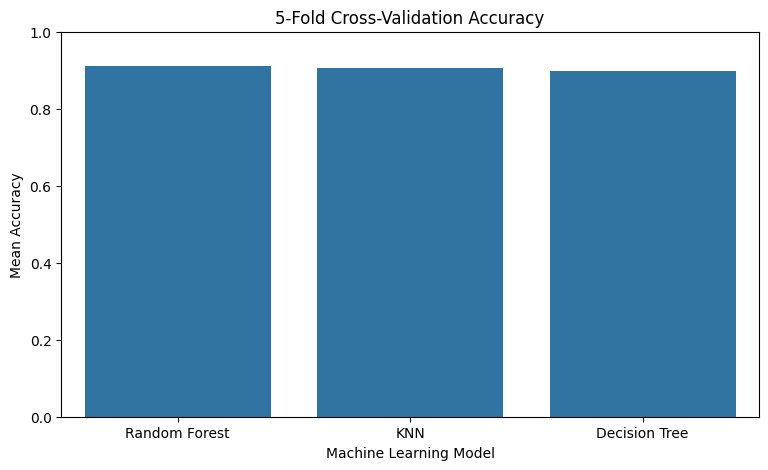

In [6]:
# Step 6: Visualize Model Comparison

plt.figure(figsize=(9, 5))

sns.barplot(
    data=cv_df,
    x="Model",
    y="Mean CV Accuracy"
)

plt.title("5-Fold Cross-Validation Accuracy")
plt.xlabel("Machine Learning Model")
plt.ylabel("Mean Accuracy")
plt.ylim(0, 1)
plt.show()

In [7]:

# Step 7: Hyperparameter Tuning with GridSearchCV

from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

param_grids = {
    "KNN": {
        "model__n_neighbors": [3, 5, 7, 9, 11],
        "model__weights": ["uniform", "distance"]
    },
    "Decision Tree": {
        "max_depth": [None, 3, 5, 10],
        "min_samples_split": [2, 5, 10]
    },
    "Random Forest": {
        "n_estimators": [100, 200],
        "max_depth": [None, 5, 10],
        "min_samples_split": [2, 5]
    }
}

search_models = {
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier())
    ]),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42)
}

best_estimators = {}
tuning_results = []

for name, estimator in search_models.items():
    grid = GridSearchCV(
        estimator=estimator,
        param_grid=param_grids[name],
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    grid.fit(X_train, y_train)

    best_estimators[name] = grid.best_estimator_

    tuning_results.append({
        "Model": name,
        "Best CV Accuracy": grid.best_score_,
        "Best Parameters": grid.best_params_
    })

tuning_df = pd.DataFrame(tuning_results).sort_values(
    by="Best CV Accuracy",
    ascending=False
)

display(tuning_df)


,Model,Best CV Accuracy,Best Parameters
0,KNN,0.922460,"{'model__n_neighbors': 9, 'model__weights': 'u..."
1,Decision Tree,0.916756,"{'max_depth': None, 'min_samples_split': 5}"
2,Random Forest,0.916578,"{'max_depth': None, 'min_samples_split': 2, 'n..."


In [8]:

# Step 8: Evaluate Tuned Models on Test Data

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

test_results = []
test_predictions = {}

for name, model in best_estimators.items():
    predictions = model.predict(X_test)
    test_predictions[name] = predictions

    test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, average="weighted"
        ),
        "Recall": recall_score(
            y_test, predictions, average="weighted"
        ),
        "F1-Score": f1_score(
            y_test, predictions, average="weighted"
        )
    })

test_df = pd.DataFrame(test_results).sort_values(
    by="Accuracy", ascending=False
)

display(test_df.round(4))


,Model,Accuracy,Precision,Recall,F1-Score
2,Random Forest,0.9048,0.9190,0.9048,0.9007
0,KNN,0.8810,0.8836,0.8810,0.8766
1,Decision Tree,0.8810,0.8836,0.8810,0.8766


Selected model: Random Forest
Test accuracy: 90.48%

Classification Report:
              precision    recall  f1-score   support

           1       1.00      0.71      0.83        14
           2       0.93      1.00      0.97        14
           3       0.82      1.00      0.90        14

    accuracy                           0.90        42
   macro avg       0.92      0.90      0.90        42
weighted avg       0.92      0.90      0.90        42



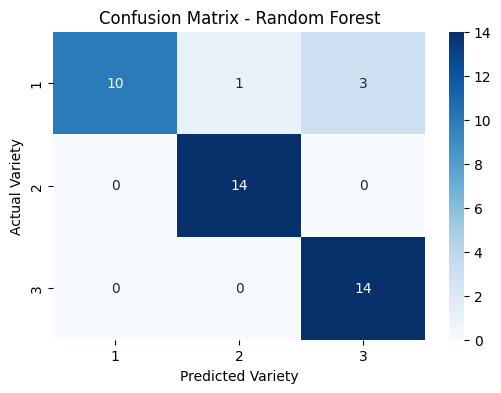

In [9]:

# Step 9: Best Model Evaluation

best_model_name = max(
    best_estimators,
    key=lambda name: accuracy_score(
        y_test, test_predictions[name]
    )
)

best_model = best_estimators[best_model_name]
final_predictions = test_predictions[best_model_name]

print("Selected model:", best_model_name)
print(f"Test accuracy: {accuracy_score(y_test, final_predictions):.2%}")

print("\nClassification Report:")
print(classification_report(y_test, final_predictions))

cm = confusion_matrix(y_test, final_predictions, labels=[1, 2, 3])

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[1, 2, 3],
    yticklabels=[1, 2, 3]
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted Variety")
plt.ylabel("Actual Variety")
plt.show()


,Feature,Importance
6,kernel_groove_length,0.209414
0,area,0.209182
1,perimeter,0.193442
4,kernel_width,0.145073
3,kernel_length,0.133980
5,asymmetry_coefficient,0.069900
2,compactness,0.039009


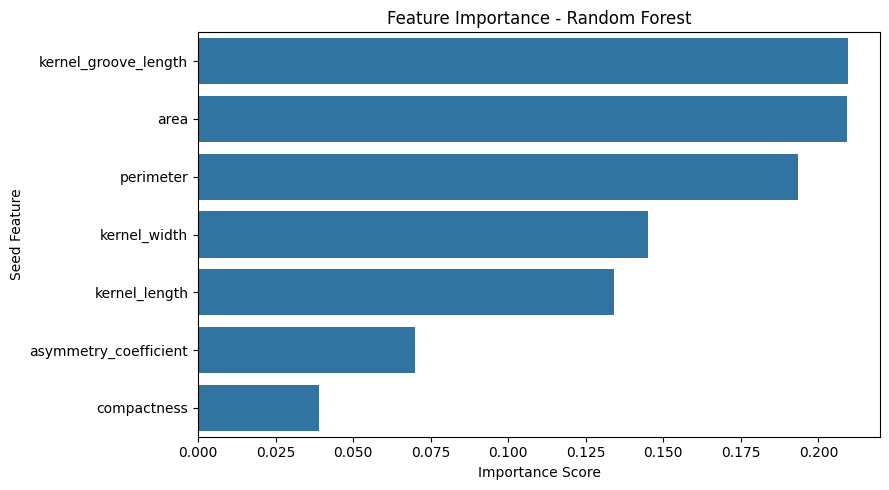

In [10]:
# Step 10: Feature Importance Analysis

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Use the tuned Random Forest model
rf_model = best_estimators["Random Forest"]

importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
}).sort_values(by="Importance", ascending=False)

display(importance_df)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Seed Feature")
plt.tight_layout()
plt.show()

In [11]:
# Step 11: Save Improved Model

import joblib

improved_model = best_estimators["Random Forest"]

joblib.dump(
    improved_model,
    "improved_wheat_seed_model.pkl"
)

print("Improved Random Forest model saved successfully!")

Improved Random Forest model saved successfully!


In [12]:
# Step 12: Load and Test Saved Model

loaded_model = joblib.load("improved_wheat_seed_model.pkl")

sample_seed = pd.DataFrame(
    [[15.2, 14.1, 0.88, 5.5, 3.2, 2.1, 5.0]],
    columns=X.columns
)

prediction = loaded_model.predict(sample_seed)

print("Predicted wheat seed variety:", prediction[0])

Predicted wheat seed variety: 1


In [13]:

import streamlit as st
import pandas as pd
import joblib
import os

st.set_page_config(
    page_title="Wheat Seed Classifier",
    page_icon="🌾",
    layout="centered"
)

st.title("🌾 Wheat Seed Classification")
st.write("Enter the seed measurements to predict its variety.")

MODEL_PATH = "improved_wheat_seed_model.pkl"

if not os.path.exists(MODEL_PATH):
    st.error("Model file not found. Keep app.py and the model file in the same folder.")
    st.stop()

model = joblib.load(MODEL_PATH)

st.subheader("Seed Measurements")

with st.form("prediction_form"):
    area = st.number_input("Area", min_value=0.0, value=15.2)
    perimeter = st.number_input("Perimeter", min_value=0.0, value=14.1)
    compactness = st.number_input("Compactness", min_value=0.0, max_value=1.0, value=0.88)
    kernel_length = st.number_input("Kernel Length", min_value=0.0, value=5.5)
    kernel_width = st.number_input("Kernel Width", min_value=0.0, value=3.2)
    asymmetry = st.number_input("Asymmetry Coefficient", min_value=0.0, value=2.1)
    groove_length = st.number_input("Kernel Groove Length", min_value=0.0, value=5.0)

    submitted = st.form_submit_button("Predict Variety")

if submitted:
    input_data = pd.DataFrame(
        [[area, perimeter, compactness, kernel_length,
          kernel_width, asymmetry, groove_length]],
        columns=[
            "area", "perimeter", "compactness", "kernel_length",
            "kernel_width", "asymmetry_coefficient",
            "kernel_groove_length"
        ]
    )

    prediction = model.predict(input_data)[0]

    st.success(f"Predicted Wheat Seed Variety: {prediction}")
    st.info("Prediction is based on the trained Machine Learning model.")


2026-10-09 08:24:14.191 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-09 08:24:14.193 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-09 08:24:16.683 
  command:

    streamlit run C:\Users\navya\AppData\Local\Programs\Python\Python310\lib\site-packages\ipykernel_launcher.py [ARGUMENTS]
2026-10-09 08:24:16.685 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-09 08:24:16.692 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-09 08:24:16.693 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-09 08:24:16.695 Thread 'MainThread': missing ScriptRunContext! This wa

In [14]:
print("Variety labels:", sorted(y.unique()))
print("Label counts:")
print(y.value_counts().sort_index())

Variety labels: [np.int64(1), np.int64(2), np.int64(3)]
Label counts:
variety
1    70
2    70
3    70
Name: count, dtype: int64


In [15]:
sample_rows = X.sample(10, random_state=42)

predictions = improved_model.predict(sample_rows)

print("Actual labels:    ", y.loc[sample_rows.index].tolist())
print("Predicted labels: ", predictions.tolist())

Actual labels:     [1, 3, 2, 3, 1, 3, 1, 3, 1, 3]
Predicted labels:  [1, 3, 2, 3, 3, 3, 1, 3, 1, 3]


In [16]:
# Get one actual sample belonging to Variety 2
sample = X[y == 2].iloc[[0]]

print(sample.to_string(index=False))
print("Actual variety:", y.loc[sample.index].iloc[0])
print("Predicted variety:", improved_model.predict(sample)[0])

 area  perimeter  compactness  kernel_length  kernel_width  asymmetry_coefficient  kernel_groove_length
17.63      15.98       0.8673          6.191         3.561                  4.076                  6.06
Actual variety: 2
Predicted variety: 2


In [18]:
variety_names = {
    1: "Kama",
    2: "Rosa",
    3: "Canadian"
}

for label in [1, 2, 3]:
    samples = X[y == label]
    found = False

    for idx in samples.index:
        sample = X.loc[[idx]]
        prediction = improved_model.predict(sample)[0]

        if prediction == label:
            print("\n" + "=" * 50)
            print(f"Variety: {label}")
            print(f"Name: {variety_names[label]}")
            print(sample.to_string(index=False))
            print(f"Predicted label: {prediction}")
            found = True
            break

    if not found:
        print(f"No correctly predicted sample found for {variety_names[label]}.")


Variety: 1
Name: Kama
 area  perimeter  compactness  kernel_length  kernel_width  asymmetry_coefficient  kernel_groove_length
15.26      14.84        0.871          5.763         3.312                  2.221                  5.22
Predicted label: 1

Variety: 2
Name: Rosa
 area  perimeter  compactness  kernel_length  kernel_width  asymmetry_coefficient  kernel_groove_length
17.63      15.98       0.8673          6.191         3.561                  4.076                  6.06
Predicted label: 2

Variety: 3
Name: Canadian
 area  perimeter  compactness  kernel_length  kernel_width  asymmetry_coefficient  kernel_groove_length
13.07      13.92        0.848          5.472         2.994                  5.304                 5.395
Predicted label: 3
